In [4]:
import pandas as pd
import numpy as np
import seaborn as sns

In [5]:
#Load dataset
df=sns.load_dataset("diamonds")

In [6]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [7]:
df.shape

(53940, 10)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [9]:
df.isnull().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


In [10]:
df.duplicated().sum()

np.int64(146)

In [11]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [12]:
df.drop_duplicates(inplace=True)

In [14]:
df.reset_index(drop=True,inplace=True)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
#Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

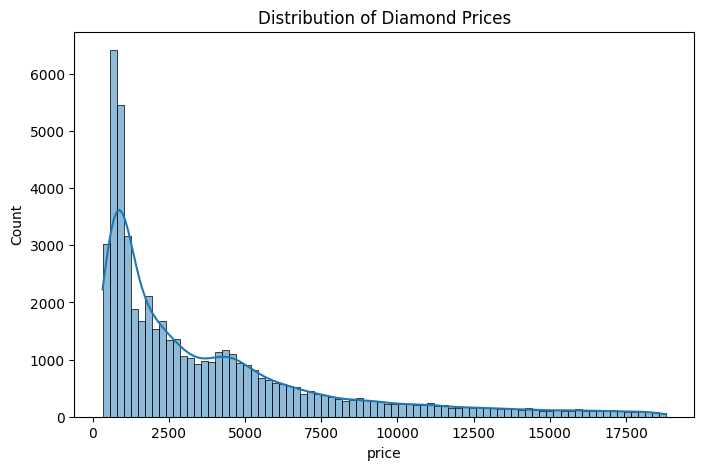

In [24]:
plt.figure(figsize=(8,5))
sns.histplot(df["price"],kde=True)
plt.title("Distribution of Diamond Prices")
plt.show()

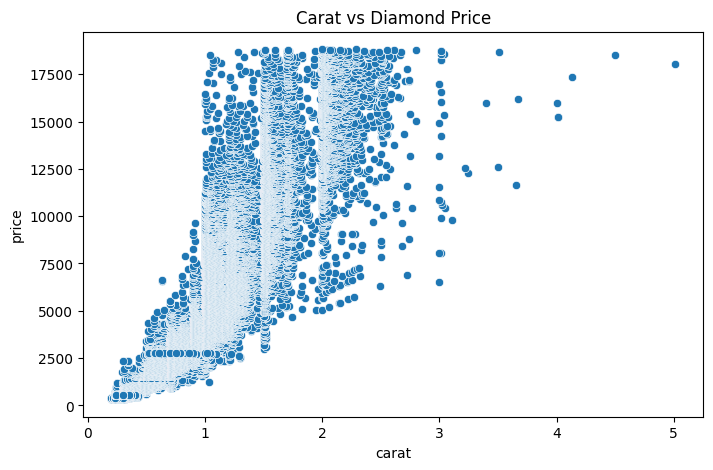

In [27]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="carat",y="price")
plt.title("Carat vs Diamond Price")
plt.show()

In [33]:
print(df.select_dtypes(include=['object','category']).columns)

Index(['cut', 'color', 'clarity'], dtype='object')


In [34]:
X=df.drop('price',axis=1)
y=df['price']

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [38]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((40345, 9), (13449, 9), (40345,), (13449,))

In [39]:
num_cols=X.select_dtypes(include=['int','float']).columns
cat_cols=X.select_dtypes(include=['category','object']).columns
print("Numerical Columns:",list(num_cols))
print("Categorical Collumns:",list(cat_cols))

Numerical Columns: ['carat', 'depth', 'table', 'x', 'y', 'z']
Categorical Collumns: ['cut', 'color', 'clarity']


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [43]:
prepocessor=ColumnTransformer(
    transformers=[('num',StandardScaler(),num_cols),
                  ('cat',OneHotEncoder(handle_unknown='ignore'),cat_cols)]
)

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

In [46]:
model=Pipeline(steps=[('preprocessor',prepocessor),
                      ('knn',KNeighborsRegressor(n_neighbors=5))])

In [47]:
model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['carat', 'depth', 'table', 'x', 'y', 'z'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['cut', 'color', 'clarity'], dtype='object'))])),
                ('knn', KNeighborsRegressor())])

In [48]:
y_pred=model.predict(X_test)

In [50]:
results=pd.DataFrame({'Actual Price':y_test.values,
                      'Predicted Price':y_pred})
print(results.head(10))

   Actual Price  Predicted Price
0          1435           2189.6
1          3584           3952.2
2          1851           1786.8
3          1590           1646.4
4          5690           5240.0
5           596            659.4
6           492            575.0
7          2063           2310.4
8           970           1328.4
9          4796           4680.0


In [51]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [52]:
mae=mean_absolute_error(y_test,y_pred)

In [53]:
mse=mean_squared_error(y_test,y_pred)

In [54]:
rmse=np.sqrt(mse)

In [55]:
r2=r2_score(y_test,y_pred)

In [56]:
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 400.5043051527995
RMSE: 769.5048409016127
R2 Score: 0.9614744152624142


In [57]:
import pickle

In [58]:
with open('diamond_price_model.pkl', 'wb') as file:
    pickle.dump(model, file)
print("Model saved successfully!")

Model saved successfully!


In [59]:
with open('diamond_price_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

In [61]:
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)
print("Predicted Diamond Price:", prediction[0])

Predicted Diamond Price: 2189.6


In [62]:
from google.colab import files
files.download("diamond_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>